<a href="https://colab.research.google.com/github/rokeya160210/Skin-Cancer-2-papers-comparison/blob/main/SEED1000_EViT_Dens169_revision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# REVISION COPY — EViT-Dens169, seed 1000

This is your original `SEED42_EViT_Dens169.ipynb`. **The model, preprocessing, data pipeline, training loop and evaluation are unchanged.** Only three things changed:

1. `CFG.SEED = 1000` (reviewer #10: seeds 42, 1000, 50000, 2024, 31415).
2. **Resume-safe on Google Drive** (cell right after CONFIG, plus a guard in section 10). Checkpoints, the BackupAndRestore state and `outputs/` go to `MyDrive/evit_runs/seed1000/`. After a disconnect, reopen the notebook and **Run all**: training continues from the last completed epoch. Once training has finished, a `TRAINING_DONE` flag stops any later "Run all" from training again. The preprocessing cache stays on the local Colab disk as before. After a disconnect it is rebuilt automatically, which takes about an hour of CPU time, but no training is repeated.
3. **Robust dataset download** (first code cells): uses the folder the download actually returns instead of a fixed cache path, so HAM10000 is always found.
4. **Revision export cells at the end** (sections R1–R3). They write probabilities in the ensemble's class order, check that the Derm7pt order matches the ensemble runs, evaluate the final-epoch checkpoint as a sensitivity analysis (reviewer #7), plot the training trajectories, and write a manifest documenting the protocol (reviewer #11).

Seeds 42 / 1000 / 50000: if you still have their `outputs/y_prob.npy` **and** `derm7pt_test_mapping.csv`, notebook 03 can use those and you don't need to re-run. If they were lost with the Colab session, re-run these copies. Op determinism is on, so with the same GPU type (you used an NVIDIA L4) and the same TensorFlow version (2.20.0) the printed metrics should match Table XVI. If Colab has since changed GPU or TF version, they may differ slightly: report the re-run values and the version change.

# EViT-Dens169 — **Cross-dataset**: train on HAM10000, test on Derm7pt

Based on Halawani et al., *Scientific Reports* 15:34776 (2025). **Same model as the in-domain notebook** (Enhanced DenseNet169 + SDEB + 6-block EViT + Eq-11 fusion + softmax head — all unchanged). The only change is the **data layer**: HAM10000 is the train/val source, **Derm7pt is the external test set**.

## Why cross-dataset needs a label-mapping decision
HAM10000 has 7 classes, but Derm7pt has no `akiec`. We therefore train on the **6 classes common to HAM10000/ISIC and Derm7pt** (`mel, nv, bcc, bkl, df, vasc`); `akiec` images are dropped from HAM10000 training. Each Derm7pt diagnosis is **mapped** into these 6 classes (`map_derm7pt_label`, Section 3b — edit it if you disagree). Consequences:
- **`akiec` is excluded entirely**: dropped from HAM10000 training (no Derm7pt source). The model is a **6-class** classifier over the shared HAM/Derm7pt label set.
- **`lentigo`, `melanosis`, `miscellaneous` don't map cleanly → dropped** by default (`CFG.DROP_UNMAPPED`). This yields **963 Derm7pt test images** (BKL = 45), identical to the companion notebooks and to Saeed et al. Table 2.
- Derm7pt has dermoscopic **and** clinical images; we test on **dermoscopic** (`CFG.DERM7PT_IMAGE_COL="derm"`) to match HAM. The **same** enhancement + hair-removal preprocessing is applied to Derm7pt.

Everything else (resume-safe preprocessing cache, `BackupAndRestore` training, metrics, Grad-CAM) is identical to the in-domain notebook.

## Honest scope & reproducibility (read before citing results)
**What this is:** a *faithful re-implementation of the EViT-Dens169 architecture* evaluated under a *6-class cross-dataset external-validation* protocol (train: HAM10000, test: Derm7pt). Two claims must be kept separate:
1. **Architecture** — reproduced faithfully, with documented resolution of the paper's internal contradictions (see *Architecture fidelity* below).
2. **Experiment** — **NOT a reproduction of the paper's results.** The paper trains/tests on one internal ISIC-2018 split (7 classes) and reports 97.10% acc / 90.8% sens / 99.29% spec / 95.17% AUC; those numbers are **not directly comparable** to a zero-shot Derm7pt external test.

Use this phrasing in a write-up:

> "We re-implemented an EViT-Dens169-style hybrid architecture and evaluated it under a 6-class cross-dataset external-validation setting using HAM10000 for training and Derm7pt for testing."

Avoid: *"We 100% reproduced the original paper"* and the merged claim *"we faithfully reproduced the paper"* (the architecture is faithful; the experiment is not the paper's).

**Determinism** (`CFG.DETERMINISTIC=True`): seeds for python/numpy/tf, `TF_DETERMINISTIC_OPS`, `enable_op_determinism()`, deterministic `tf.data` (seeded `shuffle` + `sample_from_datasets`, `deterministic=True` maps), and mixed precision auto-disabled. Runs are reproducible **on the same GPU/driver/TF version**; TensorFlow does not guarantee bitwise equality across *different* hardware.

**Provenance written to `outputs/`:** `train_split.csv`, `val_split.csv`, `derm7pt_test_mapping.csv`, `dataset_signature.json` (file-list checksums to detect dataset changes), `preproc_signature.json` (blocks silent reuse of a stale preprocessing cache).

**Subjective choice to document in the paper:** the Derm7pt -> HAM mapping (`map_derm7pt_label`, Section 3b) onto the **6 shared classes** (`mel, nv, bcc, bkl, df, vasc`). `akiec` is excluded from both training and testing (no Derm7pt source); `lentigo`/`melanosis`/`miscellaneous` are dropped, giving a **963-image** external test set consistent with the companion notebooks.

## Architecture fidelity vs the paper
The **macro-architecture matches the paper**: Enhanced (pruned) DenseNet169 backbone + parallel EViT (ViT) branch (patch embedding -> positional encoding -> multi-head self-attention encoder blocks) + Spatial Detail Enhancement Block (SDEB) + feature-level fusion + softmax head.

**Implemented as specified (no deviation):** DenseNet169 dense-block/transition structure with the Table-2 pruning; EViT encoder (LayerNorm -> MHSA -> residual -> MLP -> residual); sinusoidal positional encoding; fusion + MLP classification head.

**Documented resolutions where the paper is ambiguous or internally inconsistent** (deliberate, justified, recorded for reproducibility — *not* silent deviations):

| Element | Paper as written | Problem | Resolution in this notebook |
|---|---|---|---|
| Input resolution | 224×224 (Table 2) **and** 600×450 (ViT section) | self-contradictory | single resolution **450×600** |
| SDEB combination | element-wise **sum** of 3 conv branches | branches emit 64/128/256 channels → element-wise add is **dimensionally impossible** | **concatenate → 1×1 conv** (keeps all multi-scale features; faithful in spirit) |
| EViT depth | inconsistent block count | self-contradictory | **6 encoder blocks** |

**Honest claim:** a *faithful re-implementation of the architecture with documented resolution of the paper's contradictions* — not a bit-for-bit clone (the paper provides no reference implementation).

## Scope vs the full paper (acknowledged, not missed)
This notebook intentionally differs from the paper's **experimental** setup and does not reproduce all of its analyses:
- **Data / evaluation:** HAM10000 train/val + Derm7pt **external** test (zero-shot), vs the paper's internal ISIC-2018 split → metrics are **not directly comparable**.
- **Classes:** 6 shared classes (`akiec` excluded — no Derm7pt source) vs the paper's 7.
- **Label mapping:** Derm7pt diagnoses mapped manually into the 6 HAM classes (`map_derm7pt_label`).
- **Not included vs the paper:** ablation study, statistical-significance testing (e.g. McNemar), and explainability beyond Grad-CAM. Hooks already exist for the ablation branches (`CFG.TRAIN_DENSENET_BASELINE` / `CFG.TRAIN_VIT_BASELINE`); a bootstrap-CI / McNemar cell can be added on request.

## 1. CONFIG

In [1]:
# ==== REVISION: robust dataset download =========================================
# Uses the folder kagglehub actually returns (Colab may store datasets outside ~/.cache/kagglehub),
# re-downloads if the expected file is missing, and also checks Colab's /kaggle/input mounts.
import os, glob, subprocess, sys
try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True); import kagglehub

def _has(root, filename):
    return bool(root) and os.path.isdir(root) and any(filename in fs for _, _, fs in os.walk(root))

def _get(slug, marker):
    p = kagglehub.dataset_download(slug)
    if not _has(p, marker):
        print(f"{marker} not found under {p} -> downloading {slug} again")
        p = kagglehub.dataset_download(slug, force_download=True)
    if not _has(p, marker):
        for cand in sorted(glob.glob("/kaggle/input/*")):
            if _has(cand, marker):
                p = cand; break
    if not _has(p, marker):
        raise FileNotFoundError(f"{marker} not found for {slug}. Last folder tried: {p}. "
                                "Runtime -> Disconnect and delete runtime, then Run all again.")
    print(f"{slug} -> {p}")
    return p

HAM_PATH = _get("kmader/skin-cancer-mnist-ham10000", "HAM10000_metadata.csv")
DERM_PATH = _get("menakamohanakumar/derm7pt", "meta.csv")

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
kmader/skin-cancer-mnist-ham10000 -> /kaggle/input/skin-cancer-mnist-ham10000


100%|██████████| 152M/152M [00:05<00:00, 28.7MB/s]

Extracting files...


menakamohanakumar/derm7pt -> /root/.cache/kagglehub/datasets/menakamohanakumar/derm7pt/versions/1


In [2]:
# (both datasets are downloaded in the cell above)


In [3]:
from pathlib import Path

class CFG:
    SEED = 1000
    # ---- HAM10000 = train+val source ----
    DATA_DIR     = "/root/.cache/kagglehub/datasets/kmader/skin-cancer-mnist-ham10000/versions/1"   # updated path
    VAL_FRACTION = 0.20                 # 80/20 train/val
    WORK_DIR = "/content/work"; PREP_DIR="/content/work/preprocessed"
    CKPT_DIR = "/content/work/checkpoints"; OUT_DIR="/content/work/outputs"

    # ---- Derm7pt = EXTERNAL test set ----
    DERM7PT_DIR = "/root/.cache/kagglehub/datasets/menakamohanakumar/derm7pt/versions/1"   # updated path
    DERM7PT_IMAGE_COL = "derm"          # "derm" (matches HAM) or "clinic"
    DERM7PT_OFFICIAL_TEST_ONLY = False  # True=only test_indexes.csv; False=ALL Derm7pt
    DROP_UNMAPPED = True                # drop melanosis/miscellaneous (no HAM class)

    CLASSES = ["bcc","bkl","df","mel","nv","vasc"]   # 6 classes shared by HAM10000/ISIC & Derm7pt; akiec dropped (no Derm7pt source)

    # geometry (paper-exact)
    IMG_H, IMG_W = 450, 600; PATCH = 30
    # model dims (paper-silent defaults)
    EMBED_DIM=128; NUM_HEADS=8; NUM_EVIT_BLOCKS=6; MLP_DIM=256
    FUSION_DIM=256; HEAD_MLP1=256; HEAD_MLP2=128; DROPOUT=0.3
    # enhanced DenseNet169 pruning (Table 2)
    DENSE_BLOCKS=(6,12,16); GROWTH_RATE=32; STEM_FILTERS=32
    # balancing / training (paper-silent defaults)
    TARGET_PER_CLASS=8000; PHYSICAL_AUGMENT=False
    BATCH_SIZE=8; EPOCHS=50; LEARNING_RATE=1e-4
    OPTIMIZER="adam"; LOSS="categorical_crossentropy"
    STEPS_PER_EPOCH=None; MIXED_PRECISION=True
    # ---- reproducibility / determinism ----
    LESION_LEVEL_SPLIT=True      # split HAM10000 by lesion_id (prevents same-lesion leakage)
    DETERMINISTIC=True          # publication-grade: enable_op_determinism + deterministic tf.data
                                # (auto-disables MIXED_PRECISION for bitwise stability on one GPU)
    FORCE_REBUILD_CACHE=False   # True -> wipe preprocessing cache if the preproc CONFIG changed
    # preprocessing (Eq 1-6)
    ADAPTIVE_WIN=5; HAIR_SE=9; HAIR_THRESH=10; PREPROC_ORDER="enhance_then_hair"
    SUBSET_FRACTION=1.0
    TRAIN_HYBRID=True
    TRAIN_DENSENET_BASELINE=False; TRAIN_VIT_BASELINE=False

print("CONFIG loaded. tokens/image:", (CFG.IMG_H//CFG.PATCH)*(CFG.IMG_W//CFG.PATCH))

CONFIG loaded. tokens/image: 300


In [4]:
# ==== REVISION: persist checkpoints + outputs to Google Drive =================
import os
CFG.DATA_DIR = HAM_PATH          # REVISION: the folders returned by the download cell above
CFG.DERM7PT_DIR = DERM_PATH
PERSIST_TO_DRIVE = True
if PERSIST_TO_DRIVE and os.path.isdir("/content"):
    from google.colab import drive
    drive.mount("/content/drive")
    _root = f"/content/drive/MyDrive/evit_runs/seed{CFG.SEED}"
    CFG.CKPT_DIR = f"{_root}/checkpoints"
    CFG.OUT_DIR = f"{_root}/outputs"
print("HAM10000:", CFG.DATA_DIR, "| Derm7pt:", CFG.DERM7PT_DIR)
print("SEED:", CFG.SEED, "| CKPT_DIR:", CFG.CKPT_DIR, "| OUT_DIR:", CFG.OUT_DIR, "| PREP_DIR (local):", CFG.PREP_DIR)

Mounted at /content/drive
HAM10000: /kaggle/input/skin-cancer-mnist-ham10000 | Derm7pt: /root/.cache/kagglehub/datasets/menakamohanakumar/derm7pt/versions/1
SEED: 1000 | CKPT_DIR: /content/drive/MyDrive/evit_runs/seed1000/checkpoints | OUT_DIR: /content/drive/MyDrive/evit_runs/seed1000/outputs | PREP_DIR (local): /content/work/preprocessed


## 2. Imports, seeds, GPU, resume-safe dirs

In [5]:
import os, json, math, time, random, glob, hashlib, shutil
# determinism env vars MUST be set BEFORE tensorflow is imported
os.environ["PYTHONHASHSEED"]=str(CFG.SEED)
if CFG.DETERMINISTIC:
    os.environ["TF_DETERMINISTIC_OPS"]="1"; os.environ["TF_CUDNN_DETERMINISTIC"]="1"
import numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import cv2, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, roc_auc_score,
                             precision_score, recall_score, accuracy_score)

# seed everything
random.seed(CFG.SEED); np.random.seed(CFG.SEED)
tf.keras.utils.set_random_seed(CFG.SEED)                 # seeds python/numpy/tf together
if CFG.DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()
    if CFG.MIXED_PRECISION:
        print("DETERMINISTIC=True -> forcing MIXED_PRECISION=False for bitwise stability")
        CFG.MIXED_PRECISION=False
DATA_OPTS=tf.data.Options(); DATA_OPTS.deterministic=True   # applied to every dataset below

for d in [CFG.WORK_DIR,CFG.PREP_DIR,CFG.CKPT_DIR,CFG.OUT_DIR]: Path(d).mkdir(parents=True,exist_ok=True)
gpus=tf.config.list_physical_devices("GPU"); print("TF",tf.__version__,"GPUs",gpus)
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g,True)
    except Exception as e: print(e)
if CFG.MIXED_PRECISION and gpus:
    keras.mixed_precision.set_global_policy("mixed_float16"); print("Mixed precision ON")
print("DETERMINISTIC:",CFG.DETERMINISTIC,"| MIXED_PRECISION:",CFG.MIXED_PRECISION)


DETERMINISTIC=True -> forcing MIXED_PRECISION=False for bitwise stability
TF 2.21.0 GPUs [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
DETERMINISTIC: True | MIXED_PRECISION: False


## 2b. Verify dataset paths (run first)
Confirms the two datasets are mounted where CONFIG expects. If a path is wrong, fix
`CFG.DATA_DIR` / `CFG.DERM7PT_DIR` to match what is printed under `/kaggle/input`.

In [6]:
def show_tree(root, depth=2):
    root=root.rstrip("/")
    if not os.path.isdir(root): print("  MISSING:",root); return
    base=root.count("/")
    for dp,_,fs in os.walk(root):
        d=dp.count("/")-base
        if d>depth: continue
        print("  "*d, os.path.basename(dp)+"/", f"({len(fs)} files)")

print("All mounts under kagglehub cache:")
# Updated for Colab/kagglehub cache location
for p in sorted(glob.glob("/root/.cache/kagglehub/datasets/*")):
    print("  ", p)

print("\nHAM10000 root:", CFG.DATA_DIR); show_tree(CFG.DATA_DIR)
print("\nDerm7pt root:", CFG.DERM7PT_DIR); show_tree(CFG.DERM7PT_DIR)

All mounts under kagglehub cache:
   /root/.cache/kagglehub/datasets/menakamohanakumar

HAM10000 root: /kaggle/input/skin-cancer-mnist-ham10000
 skin-cancer-mnist-ham10000/ (5 files)
   HAM10000_images_part_1/ (5000 files)
   ham10000_images_part_1/ (5000 files)
   HAM10000_images_part_2/ (5015 files)
   ham10000_images_part_2/ (5015 files)

Derm7pt root: /root/.cache/kagglehub/datasets/menakamohanakumar/derm7pt/versions/1
 1/ (0 files)
   release_v0/ (3 files)
     images/ (0 files)
     meta/ (4 files)


## 3a. Load HAM10000 (train + val source)

In [7]:
def autodetect_ham():
    # configured dir first; always fall back to a recursive scan of kagglehub cache
    roots=[r for r in [CFG.DATA_DIR] if r and os.path.isdir(r)]+["/root/.cache/kagglehub/datasets"]
    labels=None; meta_csv=None
    for root in roots:
        for csv in sorted(glob.glob(os.path.join(root,"**","*.csv"),recursive=True)):
            try: head=pd.read_csv(csv,nrows=3)
            except Exception: continue
            cols=[c.lower() for c in head.columns]
            if "image_id" in cols and "dx" in cols:
                df=pd.read_csv(csv); df.columns=[c.lower() for c in df.columns]
                keep=["image_id","dx"]+(["lesion_id"] if "lesion_id" in df.columns else [])
                labels=df[keep].rename(columns={"dx":"label"}); meta_csv=csv
                print("HAM labels:",csv); break
        if labels is not None: break
    if labels is None:
        print("HAM10000_metadata.csv not found. Tree under kagglehub cache:")
        for p in sorted(glob.glob("/root/.cache/kagglehub/datasets/**",recursive=True))[:80]: print("  ",p)
        raise FileNotFoundError("Set CFG.DATA_DIR to the folder that contains HAM10000_metadata.csv.")
    # scan images under the dataset folder holding the metadata (efficient); else all of kagglehub cache
    data_root=os.path.dirname(meta_csv); dirs,seen=[],set()
    for ext in ("*.jpg","*.jpeg","*.png","*.JPG"):
        for f in glob.glob(os.path.join(data_root,"**",ext),recursive=True):
            d=os.path.dirname(f)
            if d not in seen: seen.add(d); dirs.append(d)
    if not dirs:
        for ext in ("*.jpg","*.jpeg","*.png","*.JPG"):
            for f in glob.glob(os.path.join("/root/.cache/kagglehub/datasets","**",ext),recursive=True):
                d=os.path.dirname(f)
                if d not in seen: seen.add(d); dirs.append(d)
    def find(i):
        for d in dirs:
            for e in (".jpg",".jpeg",".png"):
                p=os.path.join(d,str(i)+e)
                if os.path.exists(p): return p
        return None
    labels["path"]=labels["image_id"].map(find)
    labels=labels.dropna(subset=["path"])
    labels=labels[labels["label"].isin(CFG.CLASSES)].reset_index(drop=True)
    print("HAM resolved:",len(labels),"| lesion_id present:","lesion_id" in labels.columns)
    print(labels["label"].value_counts())
    return labels

LABELS=autodetect_ham()

HAM labels: /kaggle/input/skin-cancer-mnist-ham10000/HAM10000_metadata.csv
HAM resolved: 9688 | lesion_id present: True
label
nv      6705
mel     1113
bkl     1099
bcc      514
vasc     142
df       115
Name: count, dtype: int64


## 3b. Load Derm7pt (external test) + map labels into the 6 shared HAM classes

**Edit `map_derm7pt_label` if you want a different mapping.** Unmapped diagnoses
(`lentigo`, `melanosis`, `miscellaneous`) are dropped. `akiec` is excluded entirely (no Derm7pt source), so this is a 6-class problem.

> **Protocol alignment (changed):** `lentigo` is **no longer folded into `bkl`**. Saeed et al. (Table 2)
> and the companion notebooks (`SEED42_PROPOSED_MODEL`, `SEED42_skin_cancer_HAM10000`) map only
> `seborrheic keratosis` to BKL, giving **BKL = 45** and a **963-image** Derm7pt test set. Mapping
> lentigo into BKL added 24 images (BKL = 69, total = 987) and made this notebook's external test set
> inconsistent with the others. All three notebooks now evaluate on the **same 963 images**.


In [8]:
def map_derm7pt_label(dx):
    d=str(dx).strip().lower()
    if d.startswith("melanoma"):                          return "mel"
    if "nevus" in d:                                       return "nv"
    if "basal cell" in d:                                  return "bcc"
    if "seborrheic keratosis" in d:                         return "bkl"
    if "dermatofibroma" in d:                              return "df"
    if "vascular" in d:                                    return "vasc"
    return None   # akiec (none), lentigo, melanosis, miscellaneous -> unmapped
                  # NOTE: lentigo is deliberately NOT mapped to bkl. Saeed et al. (Table 2)
                  # count BKL = 45 (seborrheic keratosis only) -> 963-image test set, which
                  # is what the companion notebooks use. Folding lentigo in gave 987.

def autodetect_derm7pt():
    # Use kagglehub cache path for Colab
    roots=[r for r in [CFG.DERM7PT_DIR] if r and os.path.isdir(r)]+["/root/.cache/kagglehub/datasets"]
    meta,meta_dir=None,None
    for root in roots:
        for csv in sorted(glob.glob(os.path.join(root,"**","*.csv"),recursive=True)):
            try: head=pd.read_csv(csv,nrows=3)
            except Exception: continue
            cols=[c.lower() for c in head.columns]
            if "diagnosis" in cols and ("derm" in cols or "clinic" in cols):
                meta=pd.read_csv(csv)
                _md=os.path.dirname(csv)
                meta_dir=os.path.dirname(_md) if os.path.basename(_md).lower()=="meta" else _md
                print("Derm7pt meta:",csv); break
        if meta is not None: break
    if meta is None:
        for p in glob.glob("/root/.cache/kagglehub/datasets/**",recursive=True)[:60]: print("  ",p)
        raise FileNotFoundError("Derm7pt meta.csv not found. Add dataset / set CFG.DERM7PT_DIR.")
    meta.columns=[c.lower() for c in meta.columns]
    # official test split is applied on the ORIGINAL row order (indexes refer to it)
    if CFG.DERM7PT_OFFICIAL_TEST_ONLY:
        for csv in glob.glob(os.path.join(meta_dir,"**","*test*index*.csv"),recursive=True):
            idx=pd.read_csv(csv).iloc[:,0].astype(int).values
            meta=meta.iloc[idx].reset_index(drop=True); print("official test split:",len(meta)); break

    rels=meta[CFG.DERM7PT_IMAGE_COL].astype(str).tolist()
    cand_roots=[meta_dir]+glob.glob(os.path.join(meta_dir,"**","images"),recursive=True)
    def _try(root,r):
        for p in (os.path.join(root,r), os.path.join(root,r.split("images/")[-1])):
            if os.path.exists(p): return p
        return None
    img_root=None
    for root in cand_roots:
        if sum(_try(root,r) is not None for r in rels[:20])>=10: img_root=root; break
    if img_root is not None:
        print("Derm7pt images root:",img_root)
        meta["path"]=[_try(img_root,r) for r in rels]
    else:                                  # robust fallback: match by basename anywhere
        print("Direct join failed -> basename index fallback ...")
        bindex={}
        for ext in ("*.jpg","*.jpeg","*.png","*.JPG"):
            for f in glob.glob(os.path.join(meta_dir,"**",ext),recursive=True):
                bindex.setdefault(os.path.basename(f).lower(),f)
        meta["path"]=[bindex.get(os.path.basename(r).lower()) for r in rels]

    meta["label"]=meta["diagnosis"].map(map_derm7pt_label)
    meta["image_id"]=["d7p_"+str(i) for i in range(len(meta))]
    um=meta[meta["label"].isna()]
    if len(um):
        print("Unmapped (excluded):"); print(um["diagnosis"].value_counts())
        if not CFG.DROP_UNMAPPED: raise ValueError("Set CFG.DROP_UNMAPPED=True or extend the map.")
    meta=meta.dropna(subset=["label"]).reset_index(drop=True)
    meta=meta[meta["path"].map(lambda p: bool(p) and os.path.exists(p))].reset_index(drop=True)
    if len(meta)==0: raise FileNotFoundError("No Derm7pt images resolved. Run the 'Verify paths' cell to inspect the tree.")
    return meta[["image_id","label","path"]]

DERM7PT=autodetect_derm7pt()
print("\nDerm7pt test per class:"); print(DERM7PT["label"].value_counts())
print("(modeling 6 shared classes; df/vasc typically have small Derm7pt support)")

# ---- soft integrity check: must match the companion notebooks / Saeed et al. Table 2 ----
# BKL = 45 (seborrheic keratosis ONLY -- lentigo is unmapped/dropped).
# MEL = 252 in this Derm7pt release vs 251 in the paper (one extra metastasis image).
EXPECTED_DERM7PT_COUNTS={"nv":575,"mel":252,"bkl":45,"bcc":42,"vasc":29,"df":20}   # total 963
_actual=DERM7PT["label"].value_counts().to_dict()
print("\nDerm7pt composition check (expected == companion notebooks, 963 images):")
_ok=True
for _c,_e in EXPECTED_DERM7PT_COUNTS.items():
    _a=int(_actual.get(_c,0)); _flag="OK" if _a==_e else "MISMATCH"
    if _a!=_e: _ok=False
    print(f"  {_c.upper():5s} expected {_e:4d}  actual {_a:4d}  {_flag}")
print(f"  TOTAL expected {sum(EXPECTED_DERM7PT_COUNTS.values())}  actual {len(DERM7PT)}  "
      f"{'OK' if len(DERM7PT)==sum(EXPECTED_DERM7PT_COUNTS.values()) else 'MISMATCH'}")
print("Derm7pt counts match the companion notebooks (963)." if _ok and len(DERM7PT)==963
      else "WARNING: Derm7pt composition differs -- check the dataset release and map_derm7pt_label.")

Derm7pt meta: /root/.cache/kagglehub/datasets/menakamohanakumar/derm7pt/versions/1/release_v0/meta/meta.csv
Derm7pt images root: /root/.cache/kagglehub/datasets/menakamohanakumar/derm7pt/versions/1/release_v0/images
Unmapped (excluded):
diagnosis
lentigo          24
melanosis        16
miscellaneous     8
Name: count, dtype: int64

Derm7pt test per class:
label
nv      575
mel     252
bkl      45
bcc      42
vasc     29
df       20
Name: count, dtype: int64
(modeling 6 shared classes; df/vasc typically have small Derm7pt support)

Derm7pt composition check (expected == companion notebooks, 963 images):
  NV    expected  575  actual  575  OK
  MEL   expected  252  actual  252  OK
  BKL   expected   45  actual   45  OK
  BCC   expected   42  actual   42  OK
  VASC  expected   29  actual   29  OK
  DF    expected   20  actual   20  OK
  TOTAL expected 963  actual 963  OK
Derm7pt counts match the companion notebooks (963).


### Re-running after the mapping change (no retraining required)

The mapping change affects **only the external test set**. Training and validation come from HAM10000,
which is untouched, so the trained weights in `checkpoints/hybrid_best.keras` remain valid.

`image_id` is assigned as `d7p_<original meta.csv row index>` **before** unmapped rows are dropped, so the
IDs of the 963 kept images are unchanged and the preprocessed cache in `preprocessed/test/` is still valid —
the 24 lentigo PNGs simply stop being referenced (no re-preprocessing, no cache wipe).

**To refresh the numbers:** run section 1 → 3b → 4 → 6 (cache, resumes instantly) → 7 → 9 → **11**, and set
`CFG.TRAIN_HYBRID=False` (or just skip section 10) to bypass training. The evaluation cell in section 11 also
rebuilds `test_ds` from the current `test_m` on its own, so it is safe to run directly after section 6.


## 4. Split — HAM10000 -> train/val ; Derm7pt -> test

In [9]:
if CFG.SUBSET_FRACTION<1.0:
    LABELS=(LABELS.groupby("label",group_keys=False)
            .apply(lambda g:g.sample(frac=CFG.SUBSET_FRACTION,random_state=CFG.SEED))
            .reset_index(drop=True))
if CFG.LESION_LEVEL_SPLIT and "lesion_id" in LABELS.columns:
    # split by lesion_id so the SAME lesion never appears in both train and val (no leakage)
    lesions=LABELS.drop_duplicates("lesion_id")[["lesion_id","label"]]
    tr_les,va_les=train_test_split(lesions["lesion_id"],test_size=CFG.VAL_FRACTION,
                                   stratify=lesions["label"],random_state=CFG.SEED)
    tr_les,va_les=set(tr_les),set(va_les)
    train=LABELS[LABELS["lesion_id"].isin(tr_les)].reset_index(drop=True)
    val  =LABELS[LABELS["lesion_id"].isin(va_les)].reset_index(drop=True)
    assert set(train["lesion_id"]).isdisjoint(va_les), "LESION LEAKAGE detected!"
    print(f"Lesion-level split: {len(tr_les)} train lesions / {len(va_les)} val lesions (no overlap)")
else:
    if CFG.LESION_LEVEL_SPLIT:
        print("WARNING: 'lesion_id' missing -> IMAGE-level split (possible same-lesion leakage).")
    train,val=train_test_split(LABELS,test_size=CFG.VAL_FRACTION,
                               stratify=LABELS["label"],random_state=CFG.SEED)
    train=train.reset_index(drop=True); val=val.reset_index(drop=True)
test=DERM7PT.copy()
print("train/val (HAM) =",len(train),len(val),"| test (Derm7pt) =",len(test))

# ---- LOCK & SAVE the exact splits (reproducibility) ----
train.to_csv(os.path.join(CFG.OUT_DIR,"train_split.csv"),index=False)
val.to_csv(os.path.join(CFG.OUT_DIR,"val_split.csv"),index=False)
test.to_csv(os.path.join(CFG.OUT_DIR,"derm7pt_test_mapping.csv"),index=False)

def _sig(df):
    rows=sorted((str(r.image_id),str(r.label),
                 os.path.getsize(r.path) if os.path.exists(r.path) else -1)
                for r in df.itertuples())
    return hashlib.md5(json.dumps(rows).encode()).hexdigest(), len(df)
sig={"train":_sig(train),"val":_sig(val),"test_derm7pt":_sig(test),
     "classes":CFG.CLASSES,"seed":CFG.SEED}
json.dump(sig,open(os.path.join(CFG.OUT_DIR,"dataset_signature.json"),"w"),indent=2)
print("Saved train_split.csv / val_split.csv / derm7pt_test_mapping.csv / dataset_signature.json")
for k,v in sig.items():
    if isinstance(v,(list,tuple)) and len(v)==2 and isinstance(v[0],str) and len(v[0])==32:
        print(f"  {k}: n={v[1]} md5={v[0][:10]}")


Lesion-level split: 5793 train lesions / 1449 val lesions (no overlap)
train/val (HAM) = 7762 1926 | test (Derm7pt) = 963
Saved train_split.csv / val_split.csv / derm7pt_test_mapping.csv / dataset_signature.json
  train: n=7762 md5=83ff57719c
  val: n=1926 md5=7b71c92213
  test_derm7pt: n=963 md5=f15a7c0f00


## 4b. Environment & version capture (provenance)
Saves `environment.json` (TF / Python / GPU / driver + metadata-CSV md5) and `requirements_freeze.txt` so the exact software/hardware stack can be reported and re-pinned.

In [10]:
import subprocess, platform, sys
def _md5(p):
    h=hashlib.md5()
    with open(p,"rb") as f:
        for ch in iter(lambda: f.read(1<<20), b""): h.update(ch)
    return h.hexdigest()
env={"tensorflow":tf.__version__,"python":platform.python_version(),
     "platform":platform.platform(),"deterministic":CFG.DETERMINISTIC,
     "mixed_precision":CFG.MIXED_PRECISION,"seed":CFG.SEED}
try: env["gpu_devices"]=[d.name for d in tf.config.list_physical_devices("GPU")]
except Exception: env["gpu_devices"]=None
try: env["gpu_name"]=subprocess.check_output(
        ["nvidia-smi","--query-gpu=name,driver_version","--format=csv,noheader"]).decode().strip()
except Exception: env["gpu_name"]=None
metas={}
# Updated search paths for Colab kagglehub cache
for pat in [os.path.join(CFG.DATA_DIR,"**","*metadata*.csv"),
            os.path.join(CFG.DERM7PT_DIR,"**","meta*.csv")]:
    for f in glob.glob(pat,recursive=True):
        try: metas[os.path.basename(f)]=_md5(f)
        except Exception: pass
env["metadata_csv_md5"]=metas
json.dump(env,open(os.path.join(CFG.OUT_DIR,"environment.json"),"w"),indent=2)
try:
    fr=subprocess.check_output([sys.executable,"-m","pip","freeze"]).decode()
    open(os.path.join(CFG.OUT_DIR,"requirements_freeze.txt"),"w").write(fr)
    env["pip_freeze_lines"]=len(fr.splitlines())
except Exception as e:
    print("pip freeze failed:",e)
print(json.dumps(env,indent=2))

{
  "tensorflow": "2.21.0",
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "deterministic": true,
  "mixed_precision": false,
  "seed": 1000,
  "gpu_devices": [
    "/physical_device:GPU:0"
  ],
  "gpu_name": "NVIDIA A100-SXM4-80GB, 580.82.07",
  "metadata_csv_md5": {
    "HAM10000_metadata.csv": "70bb67f71bd23dde0bd2eda4bdcc98e5",
    "meta.csv": "b446c953d3800bf9091d9a85146b2960"
  },
  "pip_freeze_lines": 722
}


## 5. Preprocessing — Enhancement (Eq 1-3) + Hair removal (Eq 4-6)  *(unchanged)*

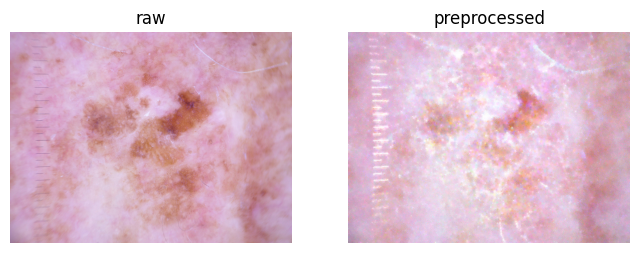

In [11]:
def adaptive_average_filter(img,win=CFG.ADAPTIVE_WIN):
    img=img.astype(np.float32); mu=cv2.blur(img,(win,win)); musq=cv2.blur(img*img,(win,win))
    var=np.maximum(musq-mu*mu,0.0); var_N=float(var.mean())
    k=np.clip((var-var_N)/(var+1e-6),0.0,1.0); return mu+k*(img-mu)
def laplacian_sharpen(img): return cv2.Laplacian(img.astype(np.float32),cv2.CV_32F,ksize=3)
def enhance(img): return np.clip(adaptive_average_filter(img)+laplacian_sharpen(img),0,255).astype(np.uint8)
def remove_hair(img,se=CFG.HAIR_SE,thr=CFG.HAIR_THRESH):
    gray=cv2.cvtColor(img,cv2.COLOR_RGB2GRAY)
    k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(se,se))
    bh=cv2.morphologyEx(gray,cv2.MORPH_BLACKHAT,k)
    _,mask=cv2.threshold(bh,thr,255,cv2.THRESH_BINARY)
    return cv2.inpaint(img,mask,3,cv2.INPAINT_TELEA)
def preprocess_one(path):
    img=cv2.cvtColor(cv2.imread(path),cv2.COLOR_BGR2RGB)
    img=cv2.resize(img,(CFG.IMG_W,CFG.IMG_H))
    if CFG.PREPROC_ORDER=="enhance_then_hair": img=remove_hair(enhance(img))
    else: img=enhance(remove_hair(img))
    return img
_d=preprocess_one(train["path"].iloc[0])
plt.figure(figsize=(8,4))
plt.subplot(1,2,1);plt.imshow(cv2.cvtColor(cv2.imread(train["path"].iloc[0]),cv2.COLOR_BGR2RGB));plt.axis("off");plt.title("raw")
plt.subplot(1,2,2);plt.imshow(_d);plt.axis("off");plt.title("preprocessed");plt.show()


## 6. Cache preprocessing — resume-safe (skips already-done images)
Same enhancement+hair-removal applied to HAM (train/val) and Derm7pt (test).

In [12]:
def cache_split(df,name):
    rows=[]; dst_dir=os.path.join(CFG.PREP_DIR,name); Path(dst_dir).mkdir(parents=True,exist_ok=True)
    for i,row in df.iterrows():
        dst=os.path.join(dst_dir,f"{row['image_id']}.png")
        if not os.path.exists(dst):
            try: cv2.imwrite(dst,cv2.cvtColor(preprocess_one(row["path"]),cv2.COLOR_RGB2BGR))
            except Exception as e: print("skip",row["image_id"],e); continue
        rows.append({"path":dst,"label":row["label"],"image_id":row["image_id"]})
        if (i+1)%500==0: print(f"  {name}:{i+1}/{len(df)}")
    man=pd.DataFrame(rows); man.to_csv(os.path.join(CFG.PREP_DIR,f"{name}_manifest.csv"),index=False); return man
# ---- guard against a STALE preprocessing cache (cache invalidation) ----
def _preproc_sig():
    keys=dict(IMG_H=CFG.IMG_H,IMG_W=CFG.IMG_W,WIN=CFG.ADAPTIVE_WIN,
              SE=CFG.HAIR_SE,THR=CFG.HAIR_THRESH,ORDER=CFG.PREPROC_ORDER)
    return hashlib.md5(json.dumps(keys,sort_keys=True).encode()).hexdigest(),keys
_sigv,_keys=_preproc_sig()
_sf=os.path.join(CFG.PREP_DIR,"preproc_signature.json")
if os.path.exists(_sf):
    _old=json.load(open(_sf))
    if _old.get("sig")!=_sigv:
        if CFG.FORCE_REBUILD_CACHE:
            print("Preprocessing CONFIG changed -> wiping stale cache.")
            shutil.rmtree(CFG.PREP_DIR); Path(CFG.PREP_DIR).mkdir(parents=True,exist_ok=True)
        else:
            raise RuntimeError("STALE CACHE: preprocessing CONFIG changed.\n"
                               f" old={_old.get('keys')}\n new={_keys}\n"
                               "Set CFG.FORCE_REBUILD_CACHE=True to rebuild, or restore the old CONFIG.")
json.dump({"sig":_sigv,"keys":_keys},open(_sf,"w"))
print("Preprocessing signature:",_sigv[:10],_keys)

t0=time.time()
train_m=cache_split(train,"train"); val_m=cache_split(val,"val"); test_m=cache_split(test,"test")
print(f"done/resumed {time.time()-t0:.0f}s |",len(train_m),len(val_m),len(test_m))


Preprocessing signature: 147f684a17 {'IMG_H': 450, 'IMG_W': 600, 'WIN': 5, 'SE': 9, 'THR': 10, 'ORDER': 'enhance_then_hair'}
  train:500/7762
  train:1000/7762
  train:1500/7762
  train:2000/7762
  train:2500/7762
  train:3000/7762
  train:3500/7762
  train:4000/7762
  train:4500/7762
  train:5000/7762
  train:5500/7762
  train:6000/7762
  train:6500/7762
  train:7000/7762
  train:7500/7762
  val:500/1926
  val:1000/1926
  val:1500/1926
  test:500/963
done/resumed 3601s | 7762 1926 963


## 7. tf.data — balanced train (HAM) ; eval (Derm7pt)  *(pipeline unchanged)*

In [13]:
CLASS_TO_IDX={c:i for i,c in enumerate(CFG.CLASSES)}; NUM_CLASSES=len(CFG.CLASSES)
AUTOTUNE=tf.data.AUTOTUNE
def _load(path,label):
    img=tf.io.decode_png(tf.io.read_file(path),channels=3)
    img=tf.image.resize(img,[CFG.IMG_H,CFG.IMG_W]); img=tf.cast(img,tf.float32)/255.0
    img=tf.ensure_shape(img,[CFG.IMG_H,CFG.IMG_W,3])   # guarantee fixed shape for batching
    return img,tf.one_hot(label,NUM_CLASSES)
def _aug(img,label):
    # NOTE: tf.image.rot90 is NOT used: a 90/270-deg rotation of a non-square (450x600)
    # image swaps H<->W (becomes 600x450) and breaks batching. A 180-deg rotation is
    # already covered by combining the horizontal + vertical flips below. For small-angle
    # rotation, see the optional, commented RandomRotation block.
    img=tf.image.random_flip_left_right(img)
    img=tf.image.random_flip_up_down(img)
    img=tf.image.random_brightness(img,0.1)
    img=tf.image.random_contrast(img,0.9,1.1)
    img=tf.image.random_saturation(img,0.9,1.1)
    img=tf.clip_by_value(img,0.0,1.0)
    img=tf.ensure_shape(img,[CFG.IMG_H,CFG.IMG_W,3])   # shape stays fixed -> batchable
    return img,label

# OPTIONAL small-angle rotation (shape-preserving). Some TF/GPU builds flag the underlying
# transform op as non-deterministic, so enable this only with CFG.DETERMINISTIC=False:
# _rot=keras.layers.RandomRotation(0.1, fill_mode="reflect", seed=CFG.SEED)
# def _aug(img,label):
#     img=tf.image.random_flip_left_right(img); img=tf.image.random_flip_up_down(img)
#     img=_rot(img, training=True)
#     img=tf.image.random_brightness(img,0.1); img=tf.image.random_contrast(img,0.9,1.1)
#     img=tf.image.random_saturation(img,0.9,1.1)
#     img=tf.clip_by_value(img,0.0,1.0)
#     return tf.ensure_shape(img,[CFG.IMG_H,CFG.IMG_W,3]),label
def make_balanced_train(man):
    per=[]
    for c in CFG.CLASSES:
        sub=man[man["label"]==c]
        if len(sub)==0: continue
        ds=tf.data.Dataset.from_tensor_slices((sub["path"].values,[CLASS_TO_IDX[c]]*len(sub)))
        per.append(ds.shuffle(len(sub),seed=CFG.SEED,reshuffle_each_iteration=True).repeat())
    ds=tf.data.Dataset.sample_from_datasets(per,weights=[1/len(per)]*len(per),seed=CFG.SEED)
    ds=ds.map(_load,num_parallel_calls=AUTOTUNE,deterministic=True)
    ds=ds.map(_aug,num_parallel_calls=AUTOTUNE,deterministic=True).with_options(DATA_OPTS)
    return ds.batch(CFG.BATCH_SIZE).prefetch(AUTOTUNE)
def make_eval(man):
    y=man["label"].map(CLASS_TO_IDX).values
    ds=tf.data.Dataset.from_tensor_slices((man["path"].values,y))
    ds=ds.map(_load,num_parallel_calls=AUTOTUNE,deterministic=True).with_options(DATA_OPTS)
    return ds.batch(CFG.BATCH_SIZE).prefetch(AUTOTUNE)
train_ds=make_balanced_train(train_m); val_ds=make_eval(val_m); test_ds=make_eval(test_m)
# one epoch ~= one balanced pass over the real training images (class balance comes from
# uniform sampling, so we do NOT need TARGET_PER_CLASS*7 steps -> that would never finish).
steps_per_epoch=CFG.STEPS_PER_EPOCH or math.ceil(len(train_m)/CFG.BATCH_SIZE)
print("steps_per_epoch:",steps_per_epoch,"| train images:",len(train_m))


steps_per_epoch: 971 | train images: 7762


## 8. Model building blocks  *(IDENTICAL to in-domain notebook — backbone unchanged)*

In [14]:
def _dense_layer(x,g):
    c=layers.BatchNormalization()(x);c=layers.Activation("relu")(c)
    c=layers.Conv2D(4*g,1,padding="same",use_bias=False)(c)
    c=layers.BatchNormalization()(c);c=layers.Activation("relu")(c)
    c=layers.Conv2D(g,3,padding="same",use_bias=False)(c); return layers.Concatenate()([x,c])
def _dense_block(x,n,g):
    for _ in range(n): x=_dense_layer(x,g)
    return x
def _transition(x):
    f=max(int(x.shape[-1]*0.5),1)
    x=layers.BatchNormalization()(x);x=layers.Activation("relu")(x)
    x=layers.Conv2D(f,1,padding="same",use_bias=False)(x); return layers.AveragePooling2D(2,2)(x)
def enhanced_densenet169(inp):
    x=layers.Conv2D(CFG.STEM_FILTERS,3,strides=2,padding="same",use_bias=False)(inp)
    x=layers.BatchNormalization()(x);x=layers.Activation("relu")(x)
    x=layers.MaxPooling2D(3,strides=2,padding="same")(x)
    for n in CFG.DENSE_BLOCKS: x=_transition(_dense_block(x,n,CFG.GROWTH_RATE))
    x=layers.Activation("relu",name="densenet_last_conv")(x)
    return layers.GlobalAveragePooling2D(name="F_Dense")(x),x
def positional_encoding(n,d):
    pos=np.arange(n)[:,None];i=np.arange(d)[None,:]
    r=1/np.power(10000,(2*(i//2))/np.float32(d));a=pos*r
    a[:,0::2]=np.sin(a[:,0::2]);a[:,1::2]=np.cos(a[:,1::2])
    return tf.constant(a[None,...],dtype=tf.float32)
def sdeb(x,d):
    f1=layers.Conv2D(64,3,padding="same",activation="relu")(x)
    f2=layers.Conv2D(128,5,padding="same",activation="relu")(x)
    f3=layers.Conv2D(256,7,padding="same",activation="relu")(x)
    return layers.Conv2D(d,1,padding="same",activation="relu")(layers.Concatenate()([f1,f2,f3]))
def evit_block(x,d,h,m,dr):
    hh=layers.LayerNormalization(epsilon=1e-6)(x)
    a=layers.MultiHeadAttention(num_heads=h,key_dim=d//h,dropout=dr)(hh,hh)
    x=layers.Add()([x,a]);hh=layers.LayerNormalization(epsilon=1e-6)(x)
    mm=layers.Dense(m,activation="gelu")(hh);mm=layers.Dropout(dr)(mm);mm=layers.Dense(d)(mm)
    return layers.Add()([x,mm])
def evit_branch(inp):
    pe=layers.Conv2D(CFG.EMBED_DIM,CFG.PATCH,strides=CFG.PATCH,padding="valid",name="patch_embed")(inp)
    pe=sdeb(pe,CFG.EMBED_DIM); gh,gw=CFG.IMG_H//CFG.PATCH,CFG.IMG_W//CFG.PATCH;n=gh*gw
    tok=layers.Reshape((n,CFG.EMBED_DIM))(pe);tok=tok+positional_encoding(n,CFG.EMBED_DIM)
    for _ in range(CFG.NUM_EVIT_BLOCKS): tok=evit_block(tok,CFG.EMBED_DIM,CFG.NUM_HEADS,CFG.MLP_DIM,CFG.DROPOUT)
    return layers.Flatten(name="F_EViT")(tok)


## 9. Hybrid model + compile  *(unchanged)*

In [15]:
def build_hybrid():
    inp=keras.Input((CFG.IMG_H,CFG.IMG_W,3),name="image")
    fd,_=enhanced_densenet169(inp); fe=evit_branch(inp)
    fused=layers.Add(name="F_fused")([layers.Dense(CFG.FUSION_DIM)(fe),layers.Dense(CFG.FUSION_DIM)(fd)])
    z=layers.LayerNormalization(epsilon=1e-6)(fused);z=layers.Flatten()(z)
    z=layers.Dropout(CFG.DROPOUT)(z);z=layers.Dropout(CFG.DROPOUT)(z)
    z=layers.Dense(CFG.HEAD_MLP1,activation="relu")(z);z=layers.Dropout(CFG.DROPOUT)(z)
    z=layers.Dense(CFG.HEAD_MLP2,activation="relu")(z)
    out=layers.Dense(NUM_CLASSES,activation="softmax",dtype="float32",name="pred")(z)
    return keras.Model(inp,out,name="EViT_Dens169")
tf.keras.backend.clear_session(); model=build_hybrid()
model.compile(keras.optimizers.Adam(CFG.LEARNING_RATE),CFG.LOSS,
              metrics=["accuracy",keras.metrics.AUC(name="auc",multi_label=True)])
print("params:",model.count_params())


params: 16605798


### 9b. Stale-checkpoint guard (7-class → 6-class)
Switching from 7 to 6 classes changes the softmax head width **and** the class→index mapping, so a checkpoint from a prior 7-class run cannot be resumed into this model. This cell auto-detects a head-width mismatch in any existing `checkpoints/` artifact and clears only the incompatible state (`backup/`, `hybrid_best.keras`, `hybrid_last.keras`). A matching 6-class checkpoint is left intact so legitimate resumes still work. The preprocessing cache is untouched (it is keyed on image geometry, not the class set).

In [16]:
# Clear ONLY checkpoints whose head width != current NUM_CLASSES (e.g. old 7-class runs).
import os, shutil
def _ckpt_head_units(p):
    try:
        m=keras.models.load_model(p,compile=False); u=int(m.output_shape[-1])
        del m; tf.keras.backend.clear_session(); return u
    except Exception as e:
        print("  could not inspect",os.path.basename(p),"->",e); return None
_stale=False
for _f in [os.path.join(CFG.CKPT_DIR,"hybrid_best.keras"),
           os.path.join(CFG.CKPT_DIR,"hybrid_last.keras")]:
    if os.path.exists(_f):
        _u=_ckpt_head_units(_f)
        if _u is not None and _u!=NUM_CLASSES:
            print(f"STALE: {os.path.basename(_f)} has {_u}-unit head != NUM_CLASSES={NUM_CLASSES}"); _stale=True
if _stale:
    for _p in [os.path.join(CFG.CKPT_DIR,"backup"),
               os.path.join(CFG.CKPT_DIR,"hybrid_best.keras"),
               os.path.join(CFG.CKPT_DIR,"hybrid_last.keras")]:
        if os.path.isdir(_p): shutil.rmtree(_p)
        elif os.path.exists(_p): os.remove(_p)
    print("Cleared stale 7-class checkpoints -> training will start fresh.")
else:
    print("No stale-head checkpoints found (fresh run or already 6-class).")


No stale-head checkpoints found (fresh run or already 6-class).


## 10. Resume-safe callbacks + train (re-run to resume after a disconnect)

In [17]:
# ============================================================================
# SELF-CONTAINED: this cell REBUILDS the data pipeline before training, so it
# cannot pick up a stale/old augmentation left in the kernel. The shape error
# [600,450,3] vs [450,600,3] comes from tf.image.rot90 on a non-square image;
# that op is removed here, and _fix_shape guarantees a constant shape redrgardless.
# ============================================================================
AUTOTUNE=tf.data.AUTOTUNE
CLASS_TO_IDX={c:i for i,c in enumerate(CFG.CLASSES)}; NUM_CLASSES=len(CFG.CLASSES)
def _load(path,label):
    img=tf.io.decode_png(tf.io.read_file(path),channels=3)
    img=tf.image.resize(img,[CFG.IMG_H,CFG.IMG_W]); img=tf.cast(img,tf.float32)/255.0
    return img,tf.one_hot(label,NUM_CLASSES)
def _aug(img,label):
    # NO rot90 (it transposes non-square images). 180-deg rotation = H-flip + V-flip below.
    img=tf.image.random_flip_left_right(img)
    img=tf.image.random_flip_up_down(img)
    img=tf.image.random_brightness(img,0.1)
    img=tf.image.random_contrast(img,0.9,1.1)
    img=tf.image.random_saturation(img,0.9,1.1)
    return tf.clip_by_value(img,0.0,1.0),label
def _fix_shape(img,label):
    img=tf.image.resize(img,[CFG.IMG_H,CFG.IMG_W])                 # final guarantee
    return tf.ensure_shape(img,[CFG.IMG_H,CFG.IMG_W,3]),label
def _balanced(man):
    per=[]
    for c in CFG.CLASSES:
        sub=man[man["label"]==c]
        if len(sub)==0: continue
        d=tf.data.Dataset.from_tensor_slices((sub["path"].values,[CLASS_TO_IDX[c]]*len(sub)))
        per.append(d.shuffle(len(sub),seed=CFG.SEED,reshuffle_each_iteration=True).repeat())
    d=tf.data.Dataset.sample_from_datasets(per,weights=[1/len(per)]*len(per),seed=CFG.SEED)
    d=d.map(_load,AUTOTUNE).map(_aug,AUTOTUNE).map(_fix_shape,AUTOTUNE).with_options(DATA_OPTS)
    return d.batch(CFG.BATCH_SIZE).prefetch(AUTOTUNE)
def _eval(man):
    y=man["label"].map(CLASS_TO_IDX).values
    d=tf.data.Dataset.from_tensor_slices((man["path"].values,y))
    d=d.map(_load,AUTOTUNE).map(_fix_shape,AUTOTUNE).with_options(DATA_OPTS)
    return d.batch(CFG.BATCH_SIZE).prefetch(AUTOTUNE)
train_ds=_balanced(train_m); val_ds=_eval(val_m); test_ds=_eval(test_m)
steps_per_epoch=CFG.STEPS_PER_EPOCH or math.ceil(len(train_m)/CFG.BATCH_SIZE)
# sanity: pull one train batch and assert the shape is correct before fitting
_xb,_yb=next(iter(train_ds)); assert tuple(_xb.shape[1:])==(CFG.IMG_H,CFG.IMG_W,3), _xb.shape
print("Pipeline rebuilt. batch:",_xb.shape,"| steps_per_epoch:",steps_per_epoch)

ckpt_best=os.path.join(CFG.CKPT_DIR,"hybrid_best.keras")
ckpt_last=os.path.join(CFG.CKPT_DIR,"hybrid_last.keras")
callbacks=[keras.callbacks.BackupAndRestore(os.path.join(CFG.CKPT_DIR,"backup")),
           keras.callbacks.ModelCheckpoint(ckpt_best,monitor="val_auc",mode="max",save_best_only=True,verbose=1),
           keras.callbacks.ModelCheckpoint(ckpt_last,save_best_only=False),
           keras.callbacks.CSVLogger(os.path.join(CFG.OUT_DIR,"train_log.csv"),append=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-6)]
# REVISION: never retrain a finished run. Keras deletes its BackupAndRestore backup when fit() ends,
# so without this flag a second 'Run all' would start training again from epoch 1.
DONE_FLAG = os.path.join(CFG.CKPT_DIR, "TRAINING_DONE")
if os.path.exists(DONE_FLAG):
    print("Training already finished for this seed -> skipping fit (checkpoints on Drive are used).")
elif CFG.TRAIN_HYBRID:
    if os.path.isdir(os.path.join(CFG.CKPT_DIR, "backup")):
        print("Backup found on Drive -> resuming from the last completed epoch.")
    model.fit(train_ds,validation_data=val_ds,epochs=CFG.EPOCHS,
              steps_per_epoch=steps_per_epoch,callbacks=callbacks,verbose=1)
    model.save(ckpt_last); print("done. best:",ckpt_best)
    open(DONE_FLAG, "w").write("done")


Pipeline rebuilt. batch: (8, 450, 600, 3) | steps_per_epoch: 971
Epoch 1/50
971/971 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - accuracy: 0.1783 - auc: 0.5055 - loss: 1.9615
Epoch 1: val_auc improved from None to 0.65043, saving model to /content/drive/MyDrive/evit_runs/seed1000/checkpoints/hybrid_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/evit_runs/seed1000/checkpoints/hybrid_best.keras
971/971 ━━━━━━━━━━━━━━━━━━━━ 255s 203ms/step - accuracy: 0.1743 - auc: 0.5059 - loss: 1.8904 - val_accuracy: 0.2430 - val_auc: 0.6504 - val_loss: 1.7468 - learning_rate: 1.0000e-04
Epoch 2/50
971/971 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.2172 - auc: 0.5553 - loss: 1.7893
Epoch 2: val_auc improved from 0.65043 to 0.75978, saving model to /content/drive/MyDrive/evit_runs/seed1000/checkpoints/hybrid_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/evit_runs/seed1000/checkpoints/hybrid_best.keras
971/971 ━━━━━━━━━━━━━━━━━━━━ 195s 201ms/step - accuracy: 0.23

## 11. Cross-dataset evaluation on Derm7pt (robust to any class with 0 support in the external test set)

Reports per-class AUC / Precision / Sensitivity / **F1** / Specificity plus **macro** averages
(macro Precision, macro Recall, **macro F1**, macro AUC) and overall accuracy — the same macro
convention as `SEED42_PROPOSED_MODEL`, so the two tables line up row for row on the same 963 images.


In [18]:
from sklearn.metrics import f1_score

# ---- safe to run without re-running section 10: rebuild the eval pipeline + checkpoint path ----
ckpt_best = globals().get("ckpt_best", os.path.join(CFG.CKPT_DIR,"hybrid_best.keras"))
test_ds   = _eval(test_m) if "_eval" in globals() else make_eval(test_m)
print("Evaluating on", len(test_m), "Derm7pt images |", os.path.basename(ckpt_best))

if os.path.exists(ckpt_best): model=keras.models.load_model(ckpt_best,compile=False)
y_true=np.array([CLASS_TO_IDX[l] for l in test_m["label"]])
y_prob=model.predict(test_ds,verbose=1); y_pred=y_prob.argmax(1)
def spec_per_class(cm):
    out=[];tot=cm.sum()
    for i in range(len(cm)):
        tp=cm[i,i];fn=cm[i].sum()-tp;fp=cm[:,i].sum()-tp;tn=tot-tp-fn-fp
        out.append(tn/(tn+fp+1e-9))
    return np.array(out)
cm=confusion_matrix(y_true,y_pred,labels=list(range(NUM_CLASSES)))
spec=spec_per_class(cm)
prec=precision_score(y_true,y_pred,average=None,labels=list(range(NUM_CLASSES)),zero_division=0)
sens=recall_score(y_true,y_pred,average=None,labels=list(range(NUM_CLASSES)),zero_division=0)
f1  =f1_score(y_true,y_pred,average=None,labels=list(range(NUM_CLASSES)),zero_division=0)
auc=np.full(NUM_CLASSES,np.nan)
for i in range(NUM_CLASSES):
    yi=(y_true==i).astype(int)
    if 0<yi.sum()<len(yi): auc[i]=roc_auc_score(yi,y_prob[:,i])
rep=pd.DataFrame({"Class":CFG.CLASSES,"AUC%":np.round(auc*100,2),
                  "Precision%":np.round(prec*100,2),"Sensitivity%":np.round(sens*100,2),
                  "F1%":np.round(f1*100,2),
                  "Specificity%":np.round(spec*100,2),"Support":[int((y_true==i).sum()) for i in range(NUM_CLASSES)]})
# macro row: unweighted mean over ALL 6 modelled classes (sklearn average="macro")
ov={"Class":"Overall (macro)","AUC%":round(np.nanmean(auc)*100,2),
    "Precision%":round(precision_score(y_true,y_pred,average="macro",zero_division=0)*100,2),
    "Sensitivity%":round(recall_score(y_true,y_pred,average="macro",zero_division=0)*100,2),
    "F1%":round(f1_score(y_true,y_pred,average="macro",zero_division=0)*100,2),
    "Specificity%":round(spec.mean()*100,2),"Support":len(y_true)}
rep=pd.concat([rep,pd.DataFrame([ov])],ignore_index=True)
print(rep.to_string(index=False))
present=[i for i in range(NUM_CLASSES) if (y_true==i).sum()>0]
absent=[CFG.CLASSES[i] for i in range(NUM_CLASSES) if (y_true==i).sum()==0]
macro_present={"AUC%":round(np.nanmean(auc[present])*100,2),
               "Precision%":round(prec[present].mean()*100,2),
               "Sensitivity%":round(sens[present].mean()*100,2),
               "F1%":round(f1[present].mean()*100,2),
               "Specificity%":round(spec[present].mean()*100,2)}
print("\nMacro over PRESENT classes only:",macro_present)
if absent: print("NOTE: absent in Derm7pt external test (0 support), excluded from present-macro:",absent)

# ---- headline row, same columns/averaging as SEED42_PROPOSED_MODEL (directly comparable) ----
headline={"Accuracy":round(accuracy_score(y_true,y_pred)*100,2),
          "Precision":ov["Precision%"],
          "Recall":ov["Sensitivity%"],
          "F1 score":ov["F1%"],
          "AUC":ov["AUC%"]}
print("\nOverall accuracy:",headline["Accuracy"],"%")
print("Macro F1:",headline["F1 score"],"%")
print("\nHeadline (macro) metrics on Derm7pt -- same convention as SEED42_PROPOSED_MODEL:")
print(pd.DataFrame([headline],index=["EViT-Dens169"]).round(2).to_string())

rep.to_csv(os.path.join(CFG.OUT_DIR,"metrics_derm7pt.csv"),index=False)
pd.DataFrame([headline],index=["EViT-Dens169"]).to_csv(
    os.path.join(CFG.OUT_DIR,"derm7pt_overall_metrics.csv"))
np.save(os.path.join(CFG.OUT_DIR,"y_true.npy"),y_true); np.save(os.path.join(CFG.OUT_DIR,"y_pred.npy"),y_pred)
np.save(os.path.join(CFG.OUT_DIR,"y_prob.npy"),y_prob)


Evaluating on 963 Derm7pt images | hybrid_best.keras
121/121 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step
          Class  AUC%  Precision%  Sensitivity%   F1%  Specificity%  Support
            bcc 57.72        6.25          2.38  3.45         98.37       42
            bkl 59.05       36.36          8.89 14.29         99.24       45
             df 40.44       14.29         15.00 14.63         98.09       20
            mel 63.75       32.43         66.67 43.64         50.77      252
             nv 55.05       55.56          2.61  4.98         96.91      575
           vasc 71.46        5.41         68.97 10.03         62.53       29
Overall (macro) 57.91       25.05         27.42 15.17         84.32      963

Macro over PRESENT classes only: {'AUC%': np.float64(57.91), 'Precision%': np.float64(25.05), 'Sensitivity%': np.float64(27.42), 'F1%': np.float64(15.17), 'Specificity%': np.float64(84.32)}

Overall accuracy: 21.91 %
Macro F1: 15.17 %

Headline (macro) metrics on Derm7pt -- same conventi

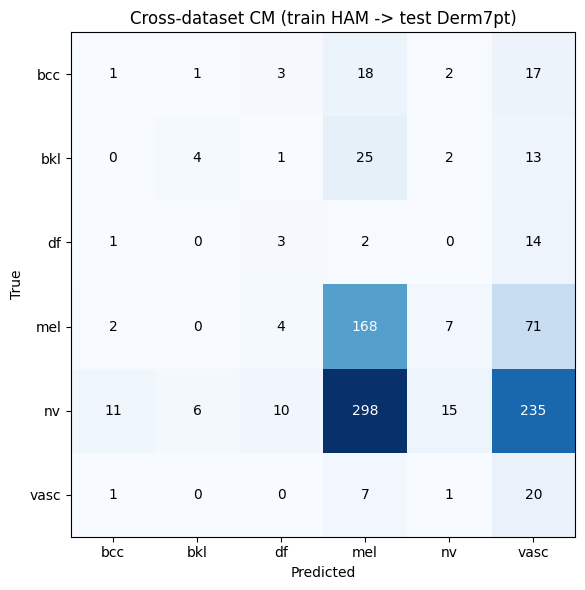

In [19]:
fig,ax=plt.subplots(figsize=(7,6)); im=ax.imshow(cm,cmap="Blues")
ax.set_xticks(range(NUM_CLASSES));ax.set_xticklabels(CFG.CLASSES)
ax.set_yticks(range(NUM_CLASSES));ax.set_yticklabels(CFG.CLASSES)
ax.set_xlabel("Predicted");ax.set_ylabel("True");ax.set_title("Cross-dataset CM (train HAM -> test Derm7pt)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j,i,cm[i,j],ha="center",va="center",color="white" if cm[i,j]>cm.max()/2 else "black")
plt.tight_layout();plt.savefig(os.path.join(CFG.OUT_DIR,"cm_derm7pt.png"),dpi=150);plt.show()




## 12. Grad-CAM (DenseNet branch)  *(unchanged)*

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 450, 600, 3))
  warnings.warn(msg)


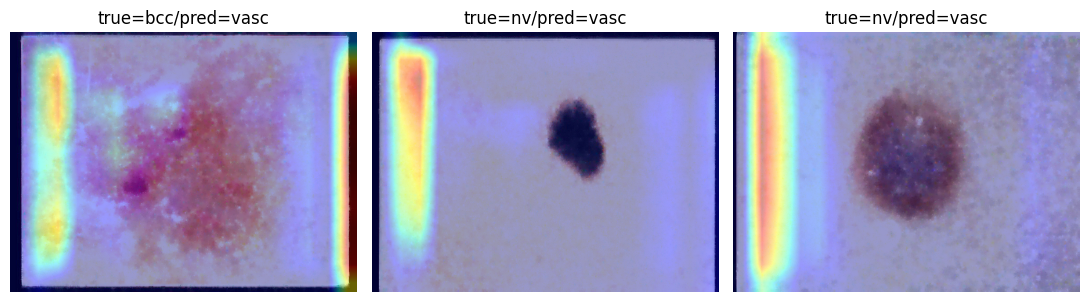

In [20]:
def grad_cam(model,img,last="densenet_last_conv",idx=None):
    gm=keras.Model(model.inputs,[model.get_layer(last).output,model.output])
    with tf.GradientTape() as t:
        co,pr=gm(img[None,...])
        if idx is None: idx=int(tf.argmax(pr[0]))
        loss=pr[:,idx]
    g=t.gradient(loss,co);p=tf.reduce_mean(g,axis=(0,1,2));co=co[0]
    h=tf.reduce_sum(co*p,axis=-1);h=tf.maximum(h,0)/(tf.reduce_max(h)+1e-9)
    return h.numpy(),idx
samp=test_m.sample(min(3,len(test_m)),random_state=CFG.SEED)
plt.figure(figsize=(11,4))
for k,(_,r) in enumerate(samp.iterrows()):
    img=cv2.resize(cv2.cvtColor(cv2.imread(r["path"]),cv2.COLOR_BGR2RGB),(CFG.IMG_W,CFG.IMG_H)).astype(np.float32)/255.
    hm,pi=grad_cam(model,img.astype(np.float32)); hm=cv2.resize(hm,(CFG.IMG_W,CFG.IMG_H))
    plt.subplot(1,len(samp),k+1);plt.imshow(img);plt.imshow(hm,cmap="jet",alpha=0.4)
    plt.title(f"true={r['label']}/pred={CFG.CLASSES[pi]}");plt.axis("off")
plt.tight_layout();plt.savefig(os.path.join(CFG.OUT_DIR,"grad_cam_derm7pt.png"),dpi=150);plt.show()


## Notes
- **Backbone/SDEB/EViT/fusion/head = unchanged** from the in-domain notebook. Only the data layer changed.
- `akiec` is **excluded** (no Derm7pt source): dropped from HAM training, absent from the 6-class softmax head, and not in the Derm7pt test set.
- Cross-dataset accuracy is normally **lower** than in-domain — different scanners, lighting, and label definitions. That gap is the point of the experiment.
- To also report **in-domain HAM** numbers for comparison, carve a HAM test split (as in the original notebook) and evaluate on it too.
- Switch `CFG.DERM7PT_IMAGE_COL="clinic"` to test clinical images instead of dermoscopic.
- **Test-set alignment (this revision):** `lentigo` is no longer mapped to `bkl`. The Derm7pt external test set
  is now **963 images** (NV 575, MEL 252, BKL 45, BCC 42, VASC 29, DF 20) — identical to
  `SEED42_PROPOSED_MODEL` and `SEED42_skin_cancer_HAM10000`, so the three models are compared on exactly the
  same images. Previously it was 987 (BKL 69).
- **Metrics:** the evaluation table now also reports per-class **F1** and **macro F1**
  (`f1_score(average="macro")`), plus a headline row using the same
  Accuracy / Precision / Recall / F1 / AUC convention as the proposed-model notebook.


## Reproducibility checklist (what is / isn't fixed)
**Fixed:** global seeds; `enable_op_determinism()`; `TF_DETERMINISTIC_OPS` + `TF_CUDNN_DETERMINISTIC`; mixed precision off under `DETERMINISTIC`; seeded `shuffle` / `sample_from_datasets`; deterministic `tf.data` maps; saved train/val/test CSVs; dataset + preprocessing checksums; resume-safe checkpoints.

**Residual / environment-dependent:** bitwise identity across different GPU models, CUDA/cuDNN, or TF versions is not guaranteed; Kaggle base-image updates can shift results; `enable_op_determinism()` slows training and disallows a few ops -> set `CFG.DETERMINISTIC=False` for speed at the cost of run-to-run variation.

**Honest reproducibility level:** high *within a pinned environment*; this is a cross-dataset external validation of the architecture, **not** a 1:1 paper reproduction.

**Recommended methods wording:** "The experimental pipeline was made reproducible by fixing random seeds, enabling TensorFlow deterministic operations, splitting HAM10000 at the lesion level, saving dataset splits and checksums, caching preprocessing with signatures, storing the Derm7pt-to-HAM test mapping, and recording the full software/hardware environment. Exact bitwise reproducibility across different hardware/software environments is not guaranteed." Claim (architecture): *"We re-implemented the EViT-Dens169 architecture faithfully, resolving the paper's internal contradictions (input resolution, SDEB branch combination, EViT depth) with documented choices."* Claim (experiment): *"We re-implemented an EViT-Dens169-style hybrid architecture and evaluated it under a 6-class cross-dataset external-validation setting using HAM10000 for training and Derm7pt for testing"* — not a reproduction of the paper's internal ISIC-2018 results.

---
# REVISION EXPORTS (R1–R3)
Run these after section 11. They only *read* the trained checkpoints and write new files. They never retrain.

In [21]:
# ==== R1. Probabilities in the ENSEMBLE class order + test-order check =======
import hashlib, json
ENSEMBLE_ORDER = ["mel", "nv", "bcc", "bkl", "df", "vasc"]          # == MEL, NV, BCC, BKL, DF, VASC
PERM = [CFG.CLASSES.index(c) for c in ENSEMBLE_ORDER]
EXPECTED_TEST_ORDER_FINGERPRINT = "bba3ea9a777c1eb1"                 # value in every ensemble manifest

assert len(test_m) == len(DERM7PT) == 963, (len(test_m), len(DERM7PT))
assert list(test_m["image_id"]) == list(DERM7PT["image_id"]), "cache order differs from DERM7PT order"
fp = hashlib.sha256("|".join(os.path.basename(p) for p in DERM7PT["path"]).encode()).hexdigest()[:16]
print("EViT test-order fingerprint:", fp)
assert fp == EXPECTED_TEST_ORDER_FINGERPRINT, "EViT scored the 963 images in a different order than the ensembles"

_ev = _eval if "_eval" in globals() else make_eval
_test_ds, _val_ds = _ev(test_m), _ev(val_m)
y_test_ens = np.array([ENSEMBLE_ORDER.index(l) for l in test_m["label"]])
y_val_ens = np.array([ENSEMBLE_ORDER.index(l) for l in val_m["label"]])
np.save(os.path.join(CFG.OUT_DIR, "y_true_ensemble_order.npy"), y_test_ens)
np.save(os.path.join(CFG.OUT_DIR, "y_val_ensemble_order.npy"), y_val_ens)

RES = {}
for tag, path, suffix in [("best_val_auc (reported)", os.path.join(CFG.CKPT_DIR, "hybrid_best.keras"), ""),
                          ("final_epoch (sensitivity)", os.path.join(CFG.CKPT_DIR, "hybrid_last.keras"), "_last")]:
    m = keras.models.load_model(path, compile=False)
    pt = m.predict(_test_ds, verbose=0)[:, PERM]
    pv = m.predict(_val_ds, verbose=0)[:, PERM]
    np.save(os.path.join(CFG.OUT_DIR, f"prob_evit_test{suffix}.npy"), pt)
    np.save(os.path.join(CFG.OUT_DIR, f"prob_evit_val{suffix}.npy"), pv)
    RES[tag] = {"test_accuracy": round(float((pt.argmax(1) == y_test_ens).mean()) * 100, 2),
                "test_macro_f1": round(f1_score(y_test_ens, pt.argmax(1), average="macro") * 100, 2),
                "val_accuracy": round(float((pv.argmax(1) == y_val_ens).mean()) * 100, 2)}
    del m; tf.keras.backend.clear_session()
print(json.dumps(RES, indent=2))

EViT test-order fingerprint: bba3ea9a777c1eb1
{
  "best_val_auc (reported)": {
    "test_accuracy": 21.91,
    "test_macro_f1": 15.17,
    "val_accuracy": 59.29
  },
  "final_epoch (sensitivity)": {
    "test_accuracy": 20.25,
    "test_macro_f1": 15.27,
    "val_accuracy": 60.8
  }
}


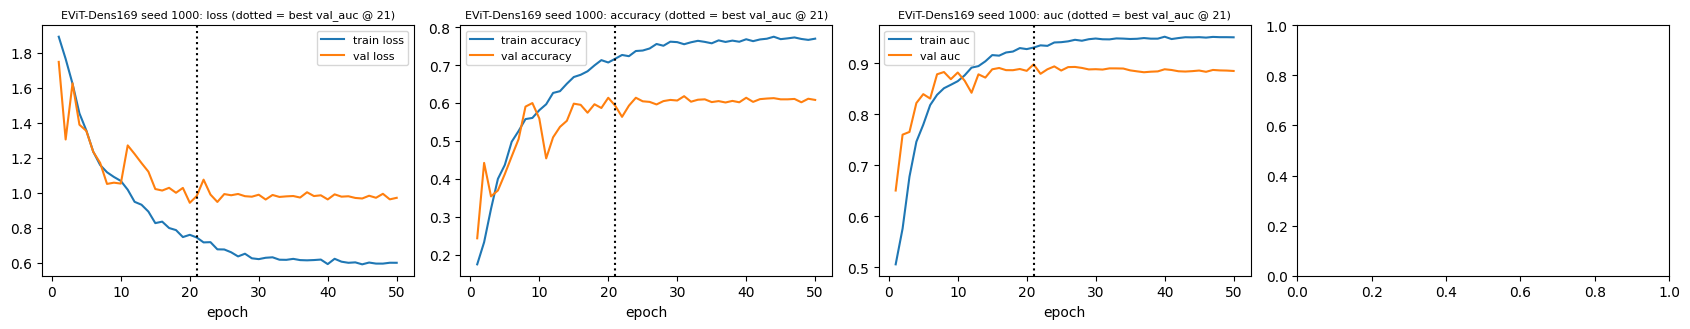

In [22]:
# ==== R2. Training / validation trajectories (reviewer #7) =====================
log = pd.read_csv(os.path.join(CFG.OUT_DIR, "train_log.csv"))
log = log.drop_duplicates("epoch", keep="last").sort_values("epoch")   # BackupAndRestore can append a resumed epoch twice
best_ep = int(log.loc[log["val_auc"].idxmax(), "epoch"]) + 1
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for a, k in zip(ax[:3], ["loss", "accuracy", "auc"]):
    a.plot(log["epoch"] + 1, log[k], label=f"train {k}"); a.plot(log["epoch"] + 1, log[f"val_{k}"], label=f"val {k}")
    a.axvline(best_ep, ls=":", c="k"); a.set_xlabel("epoch"); a.legend(fontsize=8)
    a.set_title(f"EViT-Dens169 seed {CFG.SEED}: {k} (dotted = best val_auc @ {best_ep})", fontsize=8)
lr_col = "learning_rate" if "learning_rate" in log.columns else ("lr" if "lr" in log.columns else None)
if lr_col:
    ax[3].semilogy(log["epoch"] + 1, log[lr_col]); ax[3].set_title("learning rate (ReduceLROnPlateau)", fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(CFG.OUT_DIR, f"training_curves_evit_seed{CFG.SEED}.png"), dpi=200); plt.show()

In [23]:
# ==== R3. Protocol manifest (reviewer #11: architecture vs protocol) ===========
manifest = {
    "model": "EViT-Dens169 re-implementation (Halawani et al. 2025)", "seed": CFG.SEED,
    "input_resolution_HxW": [CFG.IMG_H, CFG.IMG_W], "patch": CFG.PATCH,
    "tokens_per_image": (CFG.IMG_H // CFG.PATCH) * (CFG.IMG_W // CFG.PATCH),
    "evit_blocks": CFG.NUM_EVIT_BLOCKS, "embed_dim": CFG.EMBED_DIM, "heads": CFG.NUM_HEADS, "mlp_dim": CFG.MLP_DIM,
    "sdeb": "3x3(64) + 5x5(128) + 7x7(256) conv branches -> CONCATENATE -> 1x1 conv to embed_dim "
            "(paper states element-wise sum, which is dimensionally impossible for 64/128/256 channels)",
    "densenet": {"dense_blocks": list(CFG.DENSE_BLOCKS), "growth_rate": CFG.GROWTH_RATE, "init": "random (trained from scratch)"},
    "fusion": "Dense(256) on each branch -> element-wise Add -> LayerNorm -> MLP(256,128) -> softmax",
    "total_params": int(model.count_params()) if "model" in globals() else None,
    "preprocessing": {"adaptive_average_filter_window": CFG.ADAPTIVE_WIN, "laplacian_sharpen": True,
                      "hair_removal": {"blackhat_se": CFG.HAIR_SE, "threshold": CFG.HAIR_THRESH, "inpaint": "Telea r=3"},
                      "order": CFG.PREPROC_ORDER, "applied_to": "HAM10000 train/val AND Derm7pt test"},
    "split": {"level": "lesion" if CFG.LESION_LEVEL_SPLIT else "image", "val_fraction": CFG.VAL_FRACTION,
              "n_train_images": int(len(train_m)), "n_val_images": int(len(val_m)), "n_test": int(len(test_m))},
    "imbalance": "class-balanced sampling (uniform over 6 classes, tf.data.sample_from_datasets)",
    "augmentation": "h-flip, v-flip, brightness 0.1, contrast [0.9,1.1], saturation [0.9,1.1]",
    "optimizer": f"Adam lr={CFG.LEARNING_RATE}", "loss": CFG.LOSS, "batch_size": CFG.BATCH_SIZE, "epochs": CFG.EPOCHS,
    "lr_schedule": "ReduceLROnPlateau(val_loss, factor 0.5, patience 3, min_lr 1e-6)", "early_stopping": False,
    "checkpoint_reported": "max val_AUC (Keras multi-label AUC) on the lesion-disjoint HAM10000 validation split",
    "checkpoint_sensitivity": "final epoch (hybrid_last.keras)", "best_val_auc_epoch": best_ep,
    "results": RES, "test_order_fingerprint": fp, "tensorflow": tf.__version__,
}
json.dump(manifest, open(os.path.join(CFG.OUT_DIR, "manifest_revision.json"), "w"), indent=2)
print(json.dumps(manifest, indent=2))
print("\nFiles for notebook 03 are in", CFG.OUT_DIR)

{
  "model": "EViT-Dens169 re-implementation (Halawani et al. 2025)",
  "seed": 1000,
  "input_resolution_HxW": [
    450,
    600
  ],
  "patch": 30,
  "tokens_per_image": 300,
  "evit_blocks": 6,
  "embed_dim": 128,
  "heads": 8,
  "mlp_dim": 256,
  "sdeb": "3x3(64) + 5x5(128) + 7x7(256) conv branches -> CONCATENATE -> 1x1 conv to embed_dim (paper states element-wise sum, which is dimensionally impossible for 64/128/256 channels)",
  "densenet": {
    "dense_blocks": [
      6,
      12,
      16
    ],
    "growth_rate": 32,
    "init": "random (trained from scratch)"
  },
  "fusion": "Dense(256) on each branch -> element-wise Add -> LayerNorm -> MLP(256,128) -> softmax",
  "total_params": 16605798,
  "preprocessing": {
    "adaptive_average_filter_window": 5,
    "laplacian_sharpen": true,
    "hair_removal": {
      "blackhat_se": 9,
      "threshold": 10,
      "inpaint": "Telea r=3"
    },
    "order": "enhance_then_hair",
    "applied_to": "HAM10000 train/val AND Derm7pt test"
